Project: Titanic - ML from Disaster

In [ ]:
#import lib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
train_df = pd.read_csv("/content/train.csv")
test_df = pd.read_csv("/content/test.csv")

In [ ]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
train_df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
test_df.columns

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
train_df.set_index("PassengerId", inplace=True)

In [ ]:
train_df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
test_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [ ]:
test_df = pd.read_csv("/content/test.csv", index_col="PassengerId")

In [ ]:
test_df.tail()

,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,
1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
1309,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C


1.Feature Classification: Categorical vs Numerical

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


In [ ]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 418 entries, 892 to 1309
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    418 non-null    int64  
 1   Name      418 non-null    object 
 2   Sex       418 non-null    object 
 3   Age       332 non-null    float64
 4   SibSp     418 non-null    int64  
 5   Parch     418 non-null    int64  
 6   Ticket    418 non-null    object 
 7   Fare      417 non-null    float64
 8   Cabin     91 non-null     object 
 9   Embarked  418 non-null    object 
dtypes: float64(2), int64(3), object(5)
memory usage: 35.9+ KB


In [ ]:
train_df['Survived'] = train_df['Survived'].astype('category')

In [ ]:
train_df['Survived'].dtype

CategoricalDtype(categories=[0, 1], ordered=False, categories_dtype=int64)

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Survived  891 non-null    category
 1   Pclass    891 non-null    int64   
 2   Name      891 non-null    object  
 3   Sex       891 non-null    object  
 4   Age       714 non-null    float64 
 5   SibSp     891 non-null    int64   
 6   Parch     891 non-null    int64   
 7   Ticket    891 non-null    object  
 8   Fare      891 non-null    float64 
 9   Cabin     204 non-null    object  
 10  Embarked  889 non-null    object  
dtypes: category(1), float64(2), int64(3), object(5)
memory usage: 77.6+ KB


In [ ]:
features = ['Pclass', 'Sex', 'SibSp', 'Parch', 'Embarked']
def convert_cat(df,features):
    for feature in features:
        df[feature] = df[feature].astype('category')

convert_cat(train_df,features)
convert_cat(test_df,features)

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Survived  891 non-null    category
 1   Pclass    891 non-null    category
 2   Name      891 non-null    object  
 3   Sex       891 non-null    category
 4   Age       714 non-null    float64 
 5   SibSp     891 non-null    category
 6   Parch     891 non-null    category
 7   Ticket    891 non-null    object  
 8   Fare      891 non-null    float64 
 9   Cabin     204 non-null    object  
 10  Embarked  889 non-null    category
dtypes: category(6), float64(2), object(3)
memory usage: 48.2+ KB


Distribution of Numerical feature values across the samples

In [ ]:
train_df.describe()

,Age,Fare
count,714.000000,891.000000
mean,29.699118,32.204208
std,14.526497,49.693429
min,0.420000,0.000000
25%,20.125000,7.910400
50%,28.000000,14.454200
75%,38.000000,31.000000
max,80.000000,512.329200


Distribution of categorical features

In [ ]:
train_df.describe(include='category')

,Survived,Pclass,Sex,SibSp,Parch,Embarked
count,891,891,891,891,891,889
unique,2,3,2,7,7,3
top,0,3,male,0,0,S
freq,549,491,577,608,678,644


3.Exploratory Data Analysis(EDA) ( EDA để tìm hiểu được các mqh giữa các đặc trưng trong từng dữ liệu)

3.1 Correlating categorical features

In [ ]:
train_df['Survived'].value_counts().to_frame()

,count
Survived,
0,549
1,342


In [ ]:
train_df['Survived'].value_counts(normalize=True).to_frame()

,proportion
Survived,
0,0.616162
1,0.383838


sex( giới tính)

In [ ]:
train_df['Sex'].value_counts().to_frame()

,count
Sex,
male,577
female,314


In [ ]:
train_df['Sex'].value_counts(normalize=True).to_frame()

,proportion
Sex,
male,0.647587
female,0.352413


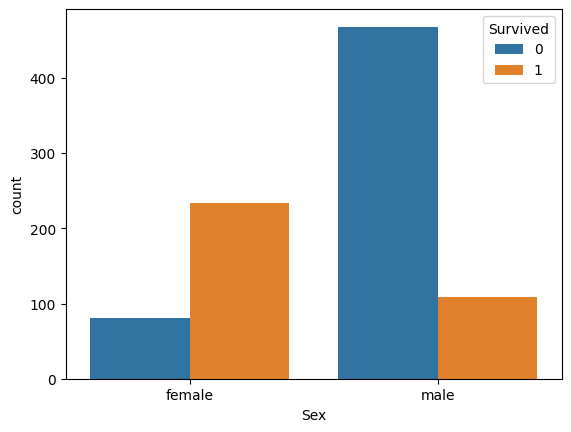

In [ ]:
sns.countplot(data=train_df, x='Sex', hue='Survived');

Remaining Categorical feature columns

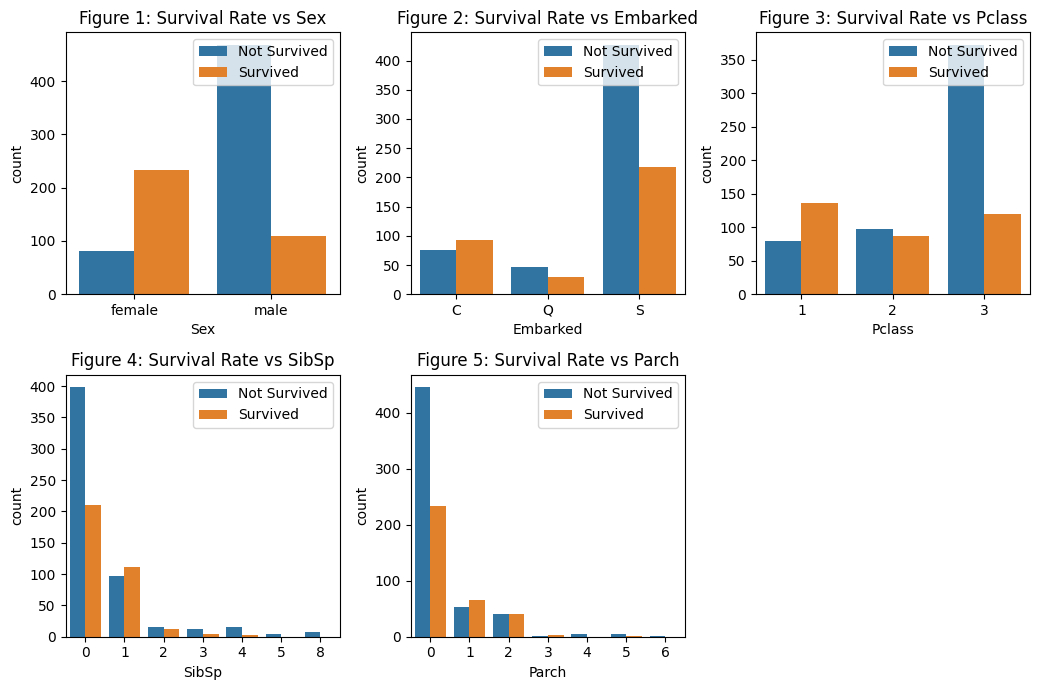

In [ ]:
cols = ['Sex', 'Embarked', 'Pclass', 'SibSp', 'Parch']
n_rows = 2
n_cols = 3
fig, ax = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.5, n_rows * 3.5))

for r in range(n_rows):
    for c in range(n_cols):
        i = r * n_cols + c #index to loop through list"cols"
        ax_i = ax[r,c]
        if i < len(cols): # for 5 subplot
            sns.countplot(data=train_df, x=cols[i], hue='Survived', ax=ax_i)
            ax_i.set_title(f"Figure {i+1}: Survival Rate vs {cols[i]}")
            ax_i.legend(title='', loc='upper right',labels=['Not Survived', 'Survived'])
        else:
            ax_i.set_visible(False) # remove the last subplot

plt.tight_layout()

Observation:
Survival Rate:
Fig1: Female survival rate > male
Fig2: Most people embarked on Southampton, and also had the highest people not survival
Fig3: 1st class higher survival rate
Fig4: People going with 0 SibSp are mostly not survived. The number of passenger with 1-2 family members has a better chance of survival
Fig5: People going with 0 Parch are mostly not survived

3.2 EDA for Numerical Features

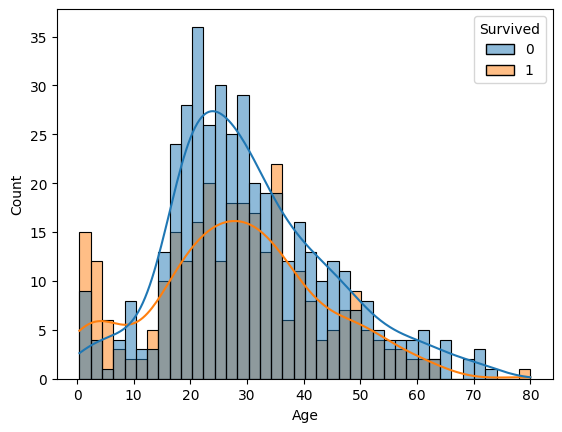

In [ ]:
sns.histplot(data=train_df, x='Age', hue='Survived', bins=40, kde=True);



*   Majority passengers wre from 18-40 ages
*   Children had more chance to survive than other ages





Fare

In [ ]:
train_df['Fare'].describe()

,Fare
count,891.000000
mean,32.204208
std,49.693429
min,0.000000
25%,7.910400
50%,14.454200
75%,31.000000
max,512.329200


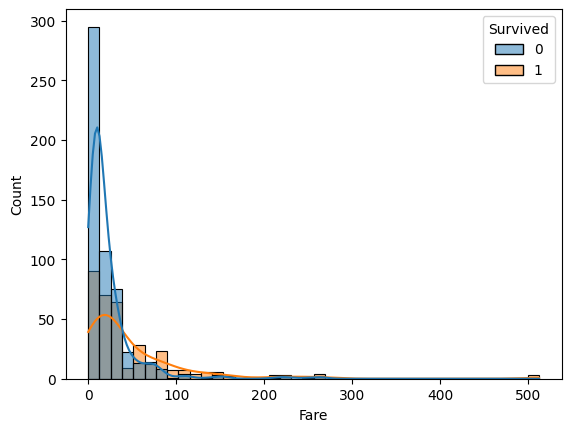

In [ ]:
sns.histplot(data=train_df, x='Fare', hue='Survived', bins=40, kde=True);

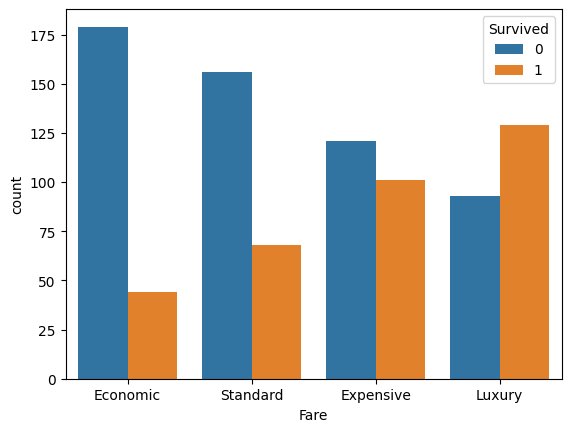

In [ ]:
#To name for 0-25$ quartile, 25-50, 50-75, 75-100
fare_categories = ['Economic', 'Standard', 'Expensive', 'Luxury']
quartitle_data = pd.qcut(train_df['Fare'], q=4, labels=fare_categories)
sns.countplot(data=train_df, x=quartitle_data, hue='Survived');

In [ ]:
quartitle_data

,Fare
PassengerId,
1,Economic
2,Luxury
3,Standard
4,Luxury
5,Standard
...,...
887,Standard
888,Expensive
889,Expensive


4.Feature Engineering & Data Wrangling

Name

*   Regular Expression

In [ ]:
train_df['Name'].tail(10)

,Name
PassengerId,
882,"Markun, Mr. Johann"
883,"Dahlberg, Miss. Gerda Ulrika"
884,"Banfield, Mr. Frederick James"
885,"Sutehall, Mr. Henry Jr"
886,"Rice, Mrs. William (Margaret Norton)"
887,"Montvila, Rev. Juozas"
888,"Graham, Miss. Margaret Edith"
889,"Johnston, Miss. Catherine Helen ""Carrie"""
890,"Behr, Mr. Karl Howell"


In [ ]:
import re #regular expression
def extract_title(name):
    p = re.compile(r", ([\w\s]+)\.")
    return p.search(name).groups(1)[0].strip()

train_df['Title']=train_df['Name'].apply(lambda name: extract_title(name))

In [ ]:
train_df['Title'].value_counts()

,count
Title,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [ ]:
train_df[train_df['Name'].str.contains('Mrs. Martin')]['Name']

,Name
PassengerId,
514,"Rothschild, Mrs. Martin (Elizabeth L. Barrett)"


In [ ]:
test_df['title'] = test_df['Name'].apply(lambda name: extract_title(name))

In [ ]:
test_df['title'].value_counts()

,count
title,
Mr,240
Miss,78
Mrs,72
Master,21
Col,2
Rev,2
Ms,1
Dr,1
Dona,1


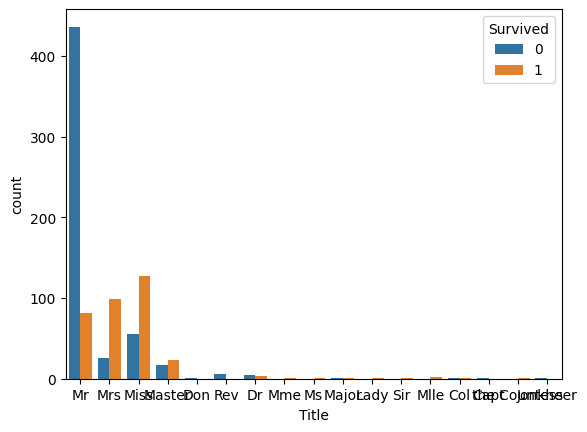

In [ ]:
sns.countplot(data=train_df, x='Title', hue='Survived');

In [ ]:
def group_title(title):
  if title in ['Mr', 'Mrs', 'Miss', 'Master']:
    return title
  elif title == 'Ms':
    return 'Miss'
  else:
    return 'Other'

test_df['Title'] = test_df['title'].apply(lambda title: group_title(title))
train_df['Title'] = train_df['Title'].apply(lambda title: group_title(title))

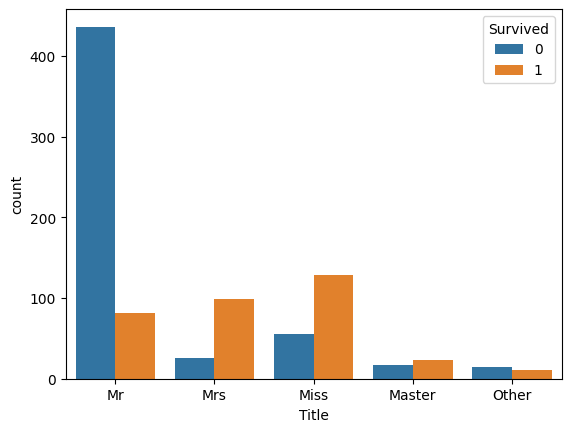

In [ ]:
sns.countplot(data=train_df, x='Title', hue='Survived');

Cols Family

*   SibSp
*   Parch



In [ ]:
train_df['Family_Size'] = train_df['SibSp'].astype('int') + train_df['Parch'].astype('int') + 1
test_df['Family_Size'] = test_df['SibSp'].astype('int') + test_df['Parch'].astype('int') + 1

In [ ]:
train_df['Family_cat'] = pd.cut(train_df['Family_Size'], bins=[0,1,4,6,20], labels=['Solo','Small','Medium','Large']) # (0,1], (1,4], (4,6], (6,20]
test_df['Family_cat'] = pd.cut(test_df['Family_Size'], bins=[0,1,4,6,20], labels=['Solo','Small','Medium','Large']) # (0,1], (1,4], (4,6], (6,20]

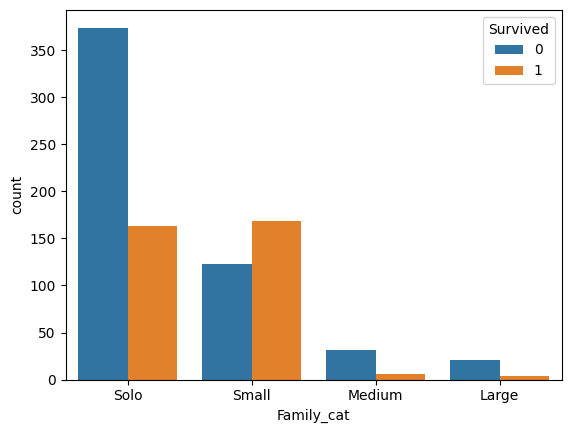

In [ ]:
sns.countplot(data=train_df, x='Family_cat', hue='Survived');

4.2 Data Wrangling

In [ ]:
num_features = ['Age', 'Fare']
cat_features = ['Sex', 'Pclass', 'Embarked', 'Title','Family_cat']
feature_cols = num_features + cat_features
print(feature_cols)

['Age', 'Fare', 'Sex', 'Pclass', 'Embarked', 'Title', 'Family_cat']


In [ ]:
def display_missing(df, feature_cols):
    n_rows = df.shape[0]
    for col in feature_cols:
        missing_count = df[col].isnull().sum()
        if missing_count > 0:
            print(f"{col}: has {missing_count*100/n_rows:.2f}% missing value")

display_missing(train_df, feature_cols)
display_missing(test_df,feature_cols)

Age: has 19.87% missing value
Embarked: has 0.22% missing value
Age: has 20.57% missing value
Fare: has 0.24% missing value


Filling missing value

Age

*   Filling missing values with median of whole dataset




In [ ]:
age_by_sex_pclass = train_df.groupby(['Sex', 'Pclass'])['Age'].median()
age_by_sex_pclass

/tmp/ipykernel_2468/1186517075.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_by_sex_pclass = train_df.groupby(['Sex', 'Pclass'])['Age'].median()


Sex     Pclass
female  1         35.0
        2         28.0
        3         21.5
male    1         40.0
        2         30.0
        3         25.0
Name: Age, dtype: float64

In [ ]:
#Filling the missing values in Age with the medians of Sex and Pclass groups

train_df['Age'] = train_df.groupby(['Sex', 'Pclass'], observed=False)['Age'].transform(lambda x: x.fillna(x.median()))
test_df['Age'] = test_df.groupby(['Sex', 'Pclass'], observed=False)['Age'].transform(lambda x: x.fillna(x.median()))

In [ ]:
display_missing(train_df, feature_cols)
display_missing(test_df,feature_cols)

Embarked: has 0.22% missing value
Fare: has 0.24% missing value


In [ ]:
X = train_df[feature_cols]
y = train_df['Survived']

In [ ]:
X_test  = test_df[feature_cols]

In [ ]:
# Preprocess pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

num_transformer = Pipeline(steps =[('imputer', SimpleImputer(strategy='median')),
                                   ('scaler', StandardScaler())])
cat_transformer = Pipeline(steps =[('imputer', SimpleImputer(strategy='most_frequent')),
                                   ('enconder', OneHotEncoder(handle_unknown='ignore'))])

In [ ]:
preprocessor = ColumnTransformer(transformers=[('num', num_transformer, num_features),
                                               ('cat', cat_transformer, cat_features)])

In [ ]:
preprocessor.fit(X)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Fare']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('enconder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Sex', 'Pclass', 'Embarked', 'Title',
                                  'Family_cat'])])

In [ ]:
X = train_df[feature_cols]
X_test = test_df[feature_cols]

#Transform dữ liệu
X = preprocessor.transform(X) #X_train, X_val
X_test = preprocessor.transform(X_test)

5. Model Training

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2)

In [ ]:
X_train.shape, X_val.shape

((712, 19), (179, 19))

In [ ]:
X_test.shape

(418, 19)

In [ ]:
#Binary classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report, confusion_matrix

In [ ]:
log_reg = LogisticRegression(solver='liblinear',max_iter=1000)
log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [ ]:
log_reg.score(X_train, y_train)

0.8370786516853933

In [ ]:
y_pred = log_reg.predict(X_val)

In [ ]:
precision_score(y_val, y_pred), recall_score(y_val, y_pred)

(0.7428571428571429, 0.7647058823529411)

In [ ]:
print(classfication_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.84      0.85       111
           1       0.74      0.76      0.75        68

    accuracy                           0.81       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179

